# EDA

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from src.utils import load_datasets

In [3]:
train_df, val_df, test_df = load_datasets()

# Exploratory Data Analysis
Each data point is a triple $(x_1, x_2, y)$ with $y\in\{0,1\}$. We have $y=1$ if $x_2$ is a paraphrase of $x_1$.

Original paper: https://arxiv.org/pdf/1904.01130

Things to check:
- number of samples
- label distribution
- sentence lengths
- how many are 'shuffled'?

**Number of samples in the dataset**

In [ ]:
split_names = ["Train", "Validation", "Test"]
split_sizes = [len(train_df), len(val_df), len(test_df)]
total = sum(split_sizes)

for i in range(len(split_names)):      
      print(split_names[i], "set:", split_sizes[i], "data points")

print("\nSplit (train|val|test) =", "{:.2f}".format((len(train_df) / total * 100)),
      "% |", "{:.2f}".format((len(val_df) / total * 100)),
      "% |", "{:.2f}".format((len(test_df) / total * 100)), "%")


Train set: 49401 data points
Validation set: 8000 data points
Test set: 8000 data points

Split (train|val|test) = 75.54 % | 12.23 % | 12.23 %


Visualization of the splits:

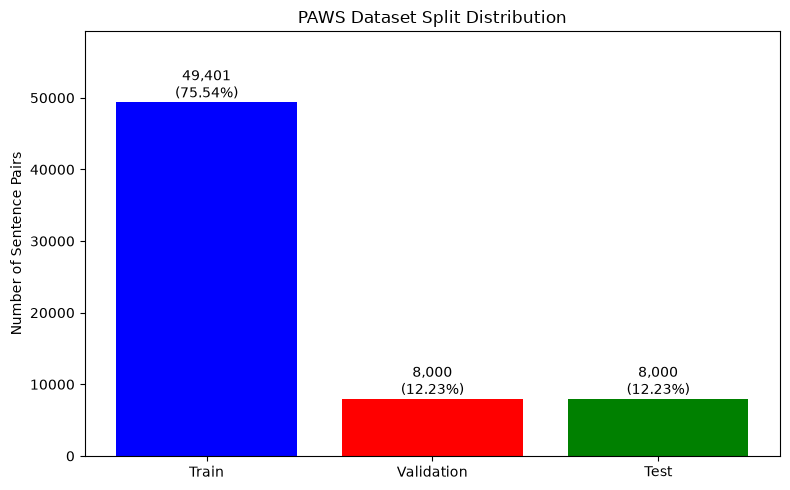

In [ ]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    split_names,
    split_sizes,
    color=["blue", "red", "green"]
)

for bar, size in zip(bars, split_sizes):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{size:,}\n({size / total * 100:.2f}%)",
        ha="center",
        va="bottom"
    )

plt.title("PAWS Dataset Split Distribution")
plt.ylabel("Number of Sentence Pairs")
plt.ylim(0, max(split_sizes) * 1.2)
plt.tight_layout()
plt.show()

**Label distribution**

Paraphrase: 1
Non-paraphrase: 0

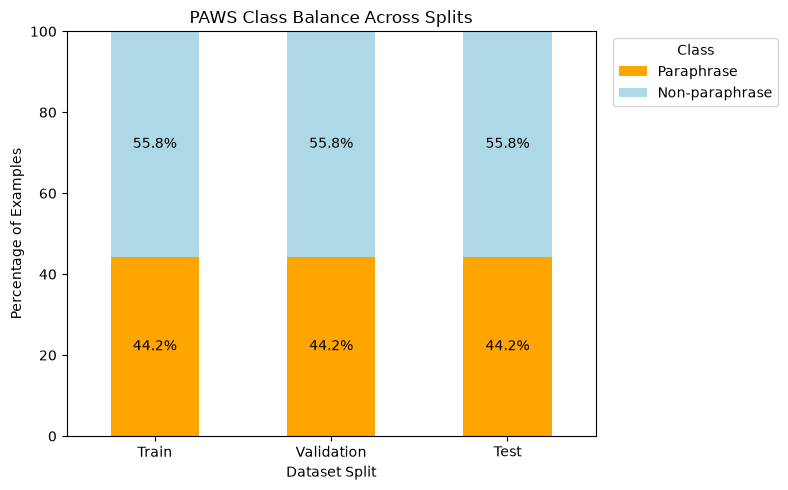

In [87]:
splits = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}

class_counts = pd.DataFrame({
    name: {
        "Paraphrase": (df["label"]).sum(),
        "Non-paraphrase": (df["label"] == 0).sum()
    }
    for name, df in splits.items()
}).T

class_percentages = class_counts.div(class_counts.sum(axis=1), axis=0) * 100

ax = class_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["orange", "lightblue"],
    rot=0
)

ax.set_title("PAWS Class Balance Across Splits")
ax.set_xlabel("Dataset Split")
ax.set_ylabel("Percentage of Examples")
ax.legend(title="Class", bbox_to_anchor=(1.02, 1), loc="upper left")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        label_type="center"
    )

plt.ylim(0, 100)
plt.tight_layout()
plt.show()

**Sentence lengths (counted in words)**

From this point, EDA is used only for the training set

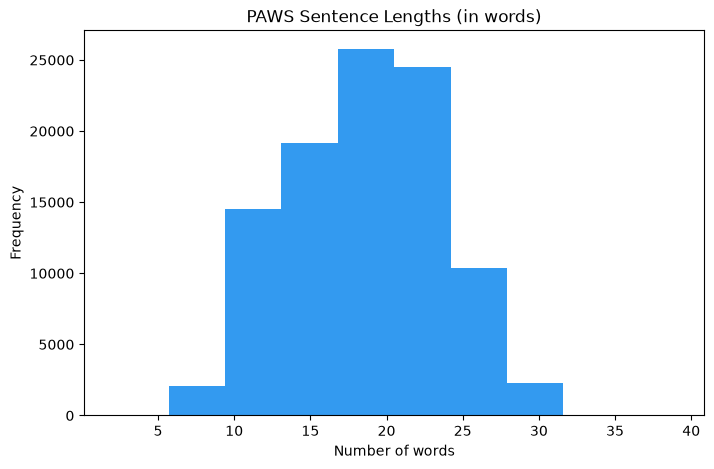

In [ ]:
words_length_1 = [len(re.findall(r"\b\w+\b", sentence)) for sentence in train_df["sentence1"]]
words_length_2 = [len(re.findall(r"\b\w+\b", sentence)) for sentence in train_df["sentence2"]]
all_sentences_words = words_length_1 + words_length_2

plt.figure(figsize=(8, 5))
plt.hist(all_sentences_words, color='#339af0')

plt.xlabel("Number of words")
plt.ylabel("Frequency")
plt.title("PAWS Sentence Lengths (in words)")

plt.show()

**Sentence lengths (counted in characters)**

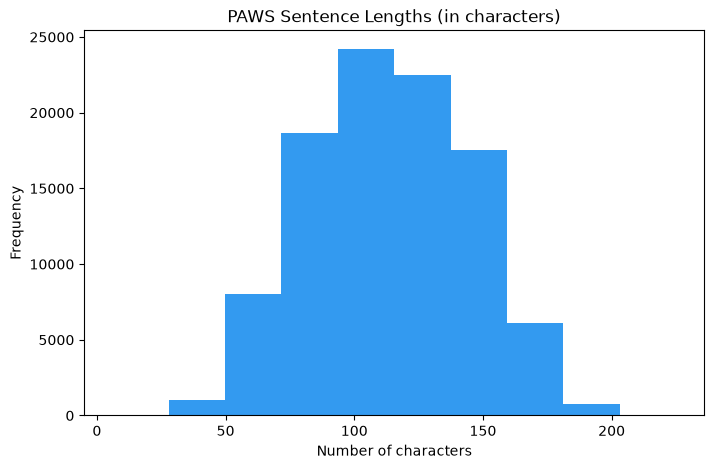

In [67]:
char_length_1 = [len(sentence) for sentence in train_df["sentence1"]]
char_length_2 = [len(sentence) for sentence in train_df["sentence2"]]
all_sentences_chars = char_length_1 + char_length_2

plt.figure(figsize=(8, 5))
plt.hist(all_sentences_chars, color='#339af0')

plt.xlabel("Number of characters")
plt.ylabel("Frequency")
plt.title("PAWS Sentence Lengths (in characters)")

plt.show()

**Shuffled data points comparison**

In [ ]:
shuffled = []

for s1, s2 in zip(train_df["sentence1"], train_df["sentence2"]):
    first_sentence = re.findall(r"\b\w+\b", s1.lower())
    second_sentence = re.findall(r"\b\w+\b", s2.lower())

    is_shuffled = sorted(first_sentence) == sorted(second_sentence) and (
        first_sentence != second_sentence)   # not counting identical token sequences
    shuffled.append(is_shuffled)

train_df["shuffled"] = shuffled

shuffled_count = sum(shuffled)

print("Shuffled pairs:", shuffled_count)
print(f"Percentage: {shuffled_count / len(train_df) * 100:.2f}%")

Shuffled pairs: 5057
Percentage: 10.24%


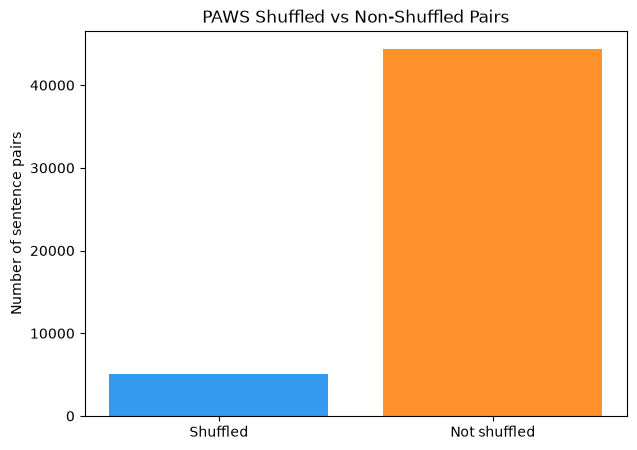

In [75]:
not_shuffled_count = len(shuffled) - shuffled_count

plt.figure(figsize=(7, 5))

plt.bar(
    ["Shuffled", "Not shuffled"],
    [shuffled_count, not_shuffled_count],
    color=["#339af0", "#ff922b"]
)

plt.ylabel("Number of sentence pairs")
plt.title("PAWS Shuffled vs Non-Shuffled Pairs")

plt.show()

Comparison of the shuffling per label:

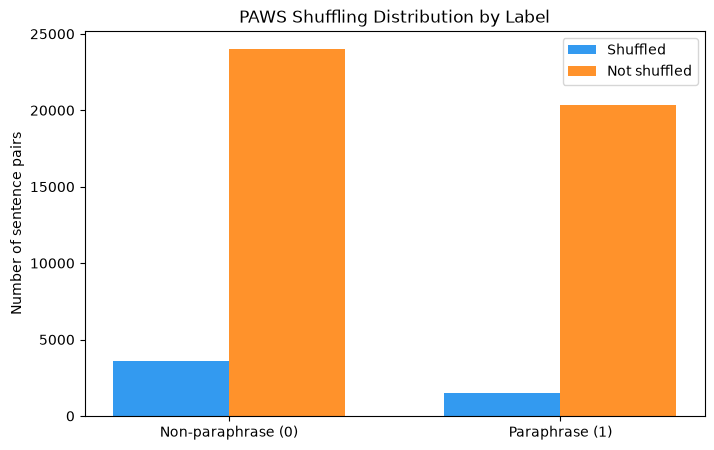

In [76]:
shuffled_per_label = train_df.groupby("label")["shuffled"].sum()
total_per_label = train_df["label"].value_counts().sort_index()

not_shuffled_per_label = total_per_label - shuffled_per_label

plt.figure(figsize=(8, 5))

x = [0, 1]
width = 0.35

plt.bar(
    [i - width/2 for i in x],
    shuffled_per_label,
    width,
    label="Shuffled",
    color="#339af0"
)

plt.bar(
    [i + width/2 for i in x],
    not_shuffled_per_label,
    width,
    label="Not shuffled",
    color="#ff922b"
)

plt.xticks([0, 1], ["Non-paraphrase (0)", "Paraphrase (1)"])
plt.ylabel("Number of sentence pairs")
plt.title("PAWS Shuffling Distribution by Label")
plt.legend()

plt.show()

**Word Overlap (by Label)**

In [77]:
def word_overlap(s1, s2):
    words1 = set(re.findall(r"\b\w+\b", s1.lower()))
    words2 = set(re.findall(r"\b\w+\b", s2.lower()))

    return len(words1 & words2) / len(words1 | words2) if words1 | words2 else 1.0

train_df["word_overlap"] = [
    word_overlap(s1, s2)
    for s1, s2 in zip(train_df["sentence1"], train_df["sentence2"])
]

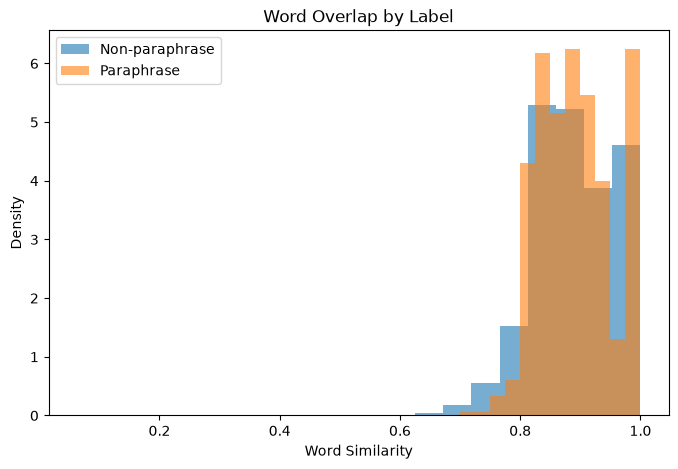

In [81]:
plt.figure(figsize=(8, 5))

for label, name in [(0, "Non-paraphrase"), (1, "Paraphrase")]:
    plt.hist(
        train_df[train_df["label"] == label]["word_overlap"],
        bins=20,
        alpha=0.6,
        density=True,
        label=name
    )

plt.xlabel("Word Similarity")
plt.ylabel("Density")
plt.title("Word Overlap by Label")
plt.legend()
plt.show()